# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
cleaned_df = pd.read_csv('data/AviationDataCleaned.csv', parse_dates=['Event.Date'])
cleaned_df.head()

/tmp/ipykernel_2784669/3393316249.py:1: DtypeWarning: Columns (6: Latitude, 7: Longitude, 25: Broad.phase.of.flight) have mixed types. Specify dtype option on import or set low_memory=False.
  cleaned_df = pd.read_csv('data/AviationDataCleaned.csv', parse_dates=['Event.Date'])


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Fraction.Serious.Fatal,Aircraft.destroyed,Make.Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,1.0,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0,Cessna - 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,Cessna - 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0,Cessna - 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,2.0,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0,Piper - PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,Cessna - 140


In [3]:
cleaned_df.shape

(59812, 32)

In [4]:
cleaned_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59812 entries, 0 to 59811
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Event.Id                59812 non-null  str           
 1   Investigation.Type      59812 non-null  str           
 2   Accident.Number         59812 non-null  str           
 3   Event.Date              59812 non-null  datetime64[us]
 4   Location                59784 non-null  str           
 5   Country                 59720 non-null  str           
 6   Latitude                22209 non-null  object        
 7   Longitude               22203 non-null  object        
 8   Airport.Code            36528 non-null  str           
 9   Airport.Name            38220 non-null  str           
 10  Injury.Severity         59812 non-null  str           
 11  Aircraft.damage         59812 non-null  str           
 12  Aircraft.Category       59812 non-null  str           
 1

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [5]:
# Plane size is a property of the plane TYPE, not of a single flight
# (a 737 on a ferry flight may carry only 2 crew). So each Make.Model is
# classified by the median number of people on board across its accidents:
#   median > 20  -> "Large"   (passenger / commercial aircraft)
#   median <= 20 -> "Small"
median_pax = cleaned_df.groupby('Make.Model')['Total.Passengers'].transform('median')
cleaned_df['Plane.Size'] = np.where(median_pax > 20, "Large", "Small")
cleaned_df['Plane.Size'].value_counts()

Plane.Size
Small    58386
Large     1426
Name: count, dtype: int64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [6]:
## Mean injury fraction per make, for each plane type
small = cleaned_df[cleaned_df['Plane.Size'] == 'Small']
counts_small = small['Make'].value_counts()
small = small[small['Make'].isin(counts_small[counts_small >= 10].index)]
small_makes = small.groupby('Make')['Fraction.Serious.Fatal'].mean().nsmallest(15)

large = cleaned_df[cleaned_df['Plane.Size'] == 'Large']
counts_large = large['Make'].value_counts()
large = large[large['Make'].isin(counts_large[counts_large >= 10].index)]
large_makes = large.groupby('Make')['Fraction.Serious.Fatal'].mean().nsmallest(15)

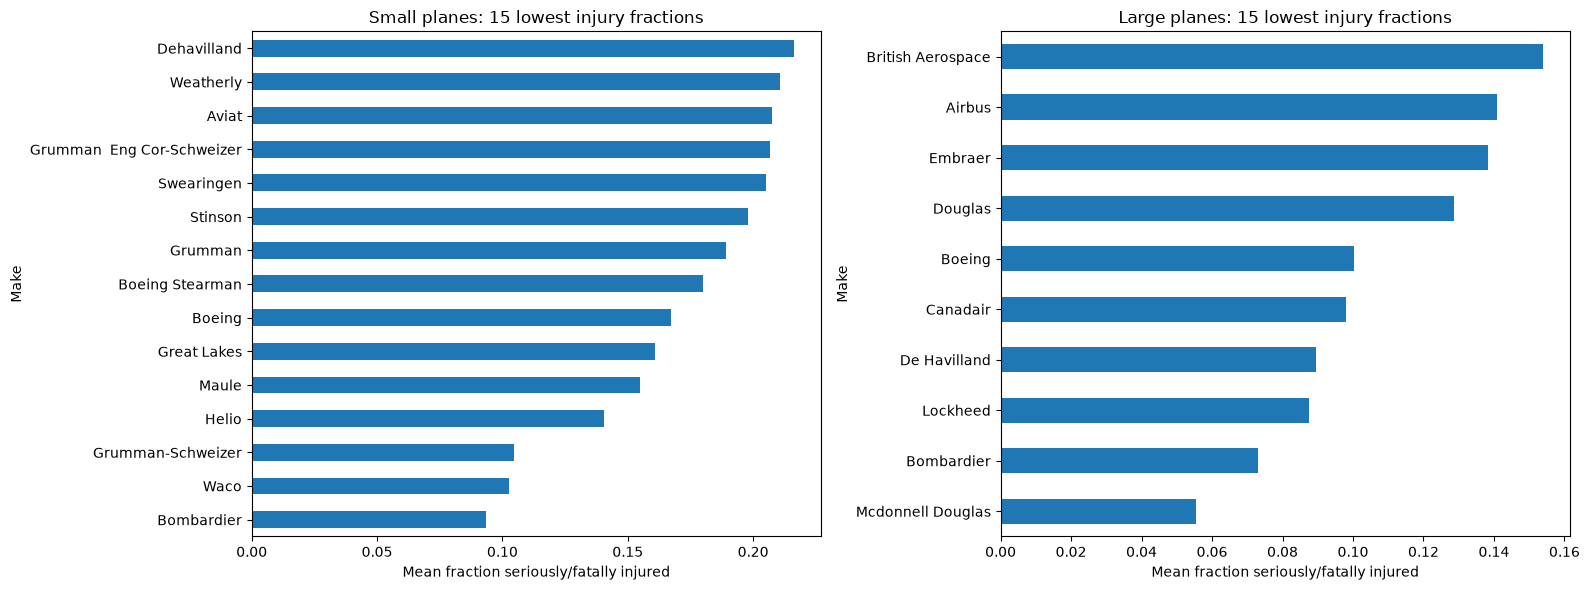

In [7]:
## Let's Plot them side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

small_makes.plot(kind='barh', ax=axes[0], title='Small planes: 15 lowest injury fractions')
large_makes.plot(kind='barh', ax=axes[1], title='Large planes: 15 lowest injury fractions')

for ax in axes:
    ax.set_xlabel('Mean fraction seriously/fatally injured')

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

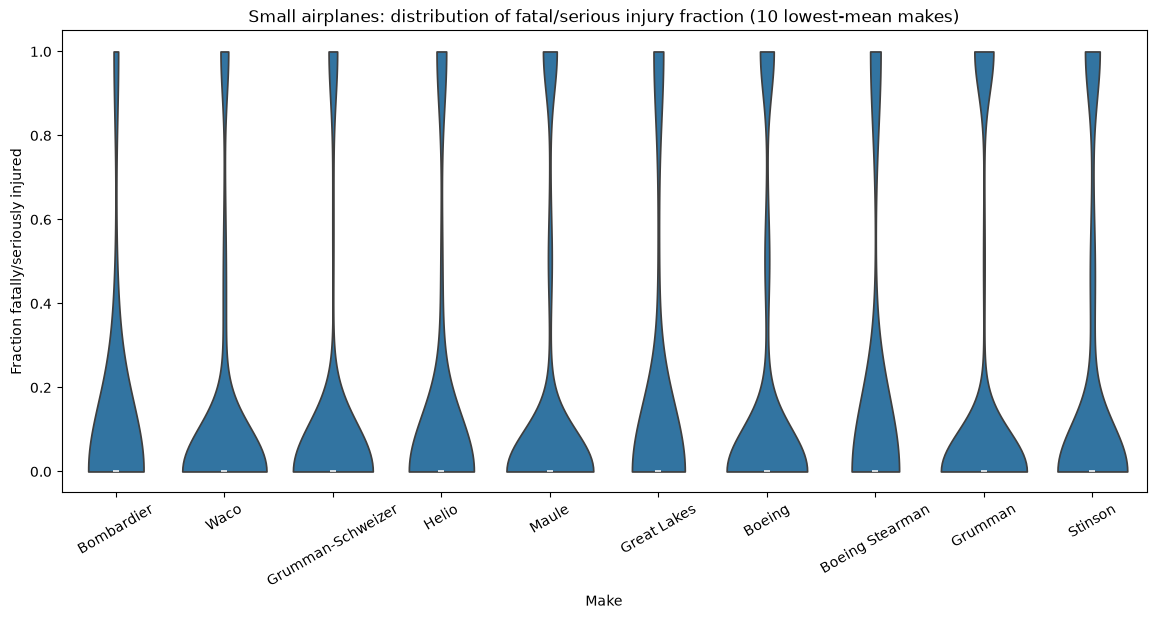

In [8]:
small = cleaned_df[cleaned_df['Plane.Size'] == 'Small']
small_top10 = small_makes.nsmallest(10).index.tolist()

fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(data=small[small["Make"].isin(small_top10)], x="Make", y="Fraction.Serious.Fatal",
               order=small_top10, cut=0, ax=ax)
ax.set_title("Small airplanes: distribution of fatal/serious injury fraction (10 lowest-mean makes)")
ax.set_xlabel("Make")
ax.set_ylabel("Fraction fatally/seriously injured")
plt.xticks(rotation=30)
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

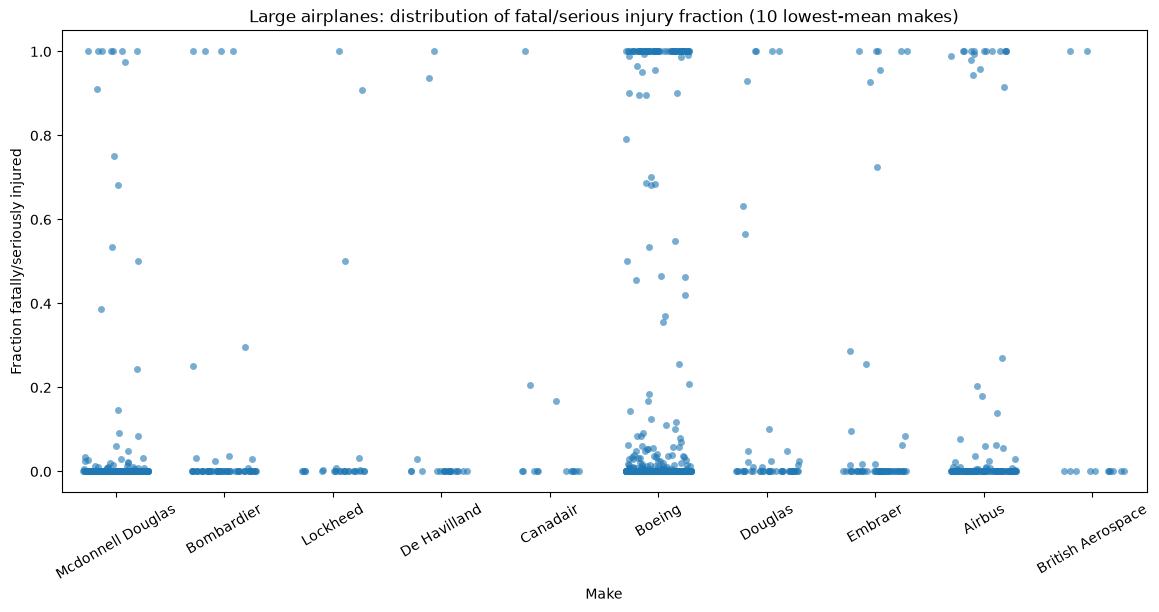

In [9]:
large = cleaned_df[cleaned_df['Plane.Size'] == 'Large']
large_top10 = large_makes.nsmallest(10).index.tolist()

fig, ax = plt.subplots(figsize=(14, 6))
sns.stripplot(data=large[large["Make"].isin(large_top10)], x="Make", y="Fraction.Serious.Fatal",
               order=large_top10, jitter=0.3, alpha=0.6, ax=ax)
ax.set_title("Large airplanes: distribution of fatal/serious injury fraction (10 lowest-mean makes)")
ax.set_xlabel("Make")
ax.set_ylabel("Fraction fatally/seriously injured")
plt.xticks(rotation=30)
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

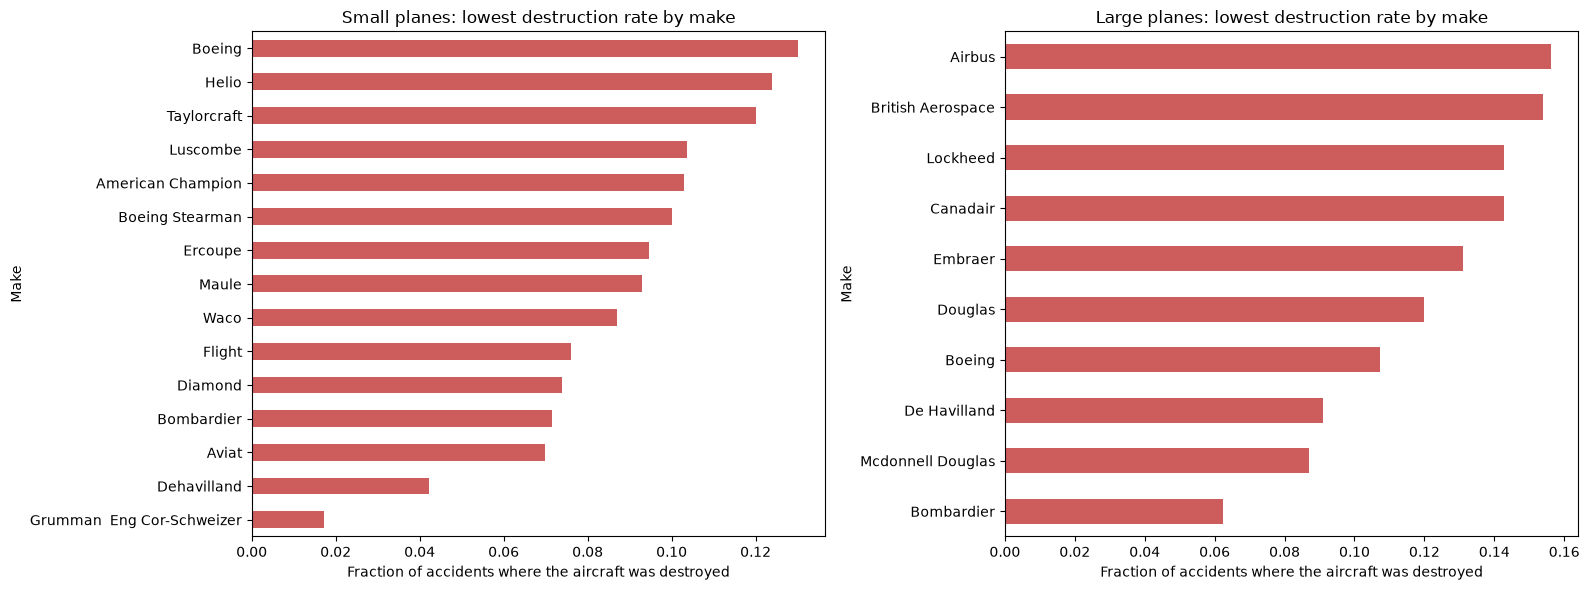

In [10]:
small = cleaned_df[cleaned_df['Plane.Size'] == 'Small']
small = small[small['Make'].isin(counts_small[counts_small >= 10].index)]

large = cleaned_df[cleaned_df['Plane.Size'] == 'Large']
large = large[large['Make'].isin(counts_large[counts_large >= 10].index)]

# Destruction rate per make (mean of a 0/1 column = fraction destroyed)
small_destroyed = small.groupby('Make')['Aircraft.destroyed'].mean().nsmallest(15)
large_destroyed = large.groupby('Make')['Aircraft.destroyed'].mean().nsmallest(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
small_destroyed.plot(kind='barh', ax=axes[0], color='indianred',
                     title='Small planes: lowest destruction rate by make')
large_destroyed.plot(kind='barh', ax=axes[1], color='indianred',
                     title='Large planes: lowest destruction rate by make')

for ax in axes:
    ax.set_xlabel('Fraction of accidents where the aircraft was destroyed')

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

#### Discussion: Makes

**Overall.** 
There is far more chance of survival on an accident in a large plane than one in a small plane

**Distributions.** 
- For the best makes, **72–89% of accidents had no serious injuries**.
- The violin plot for small makes shows a wide bulge at 0 and a smaller one at 1. The strip plot for large makes shows a dense band of dots at 0 with a few scattered at 1.
- So a make's mean injury fraction mainly reflects **how often its accidents are catastrophic**, not how badly people are usually hurt.

**Small airplane makes**
- **Lowest injury fraction:** Waco, Grumman-Schweizer, Helio, Maule and Great Lakes.
- **Lowest destruction rate:** Aviat, Diamond, Maule and Waco.

- **Recommendation: Maule, Aviat and Diamond.**
  - All three are still in production and have good numbers.
  - Maule have a low injury fraction, a low destruction rate, which makes it the most reliable result.
  - Aviat and Diamond have the lowest destruction rates and injury fractions below the small-plane average.

**Large airplane makes**
- All the major airliner manufacturers have **low and similar** injury fractions.
- **Recommendation: Boeing and Bombardier.**
  - **Bombardier** has the lowest destruction rate and the second-lowest injury fraction.
  - **Boeing** has by far the largest sample, so its low values are the most reliable.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

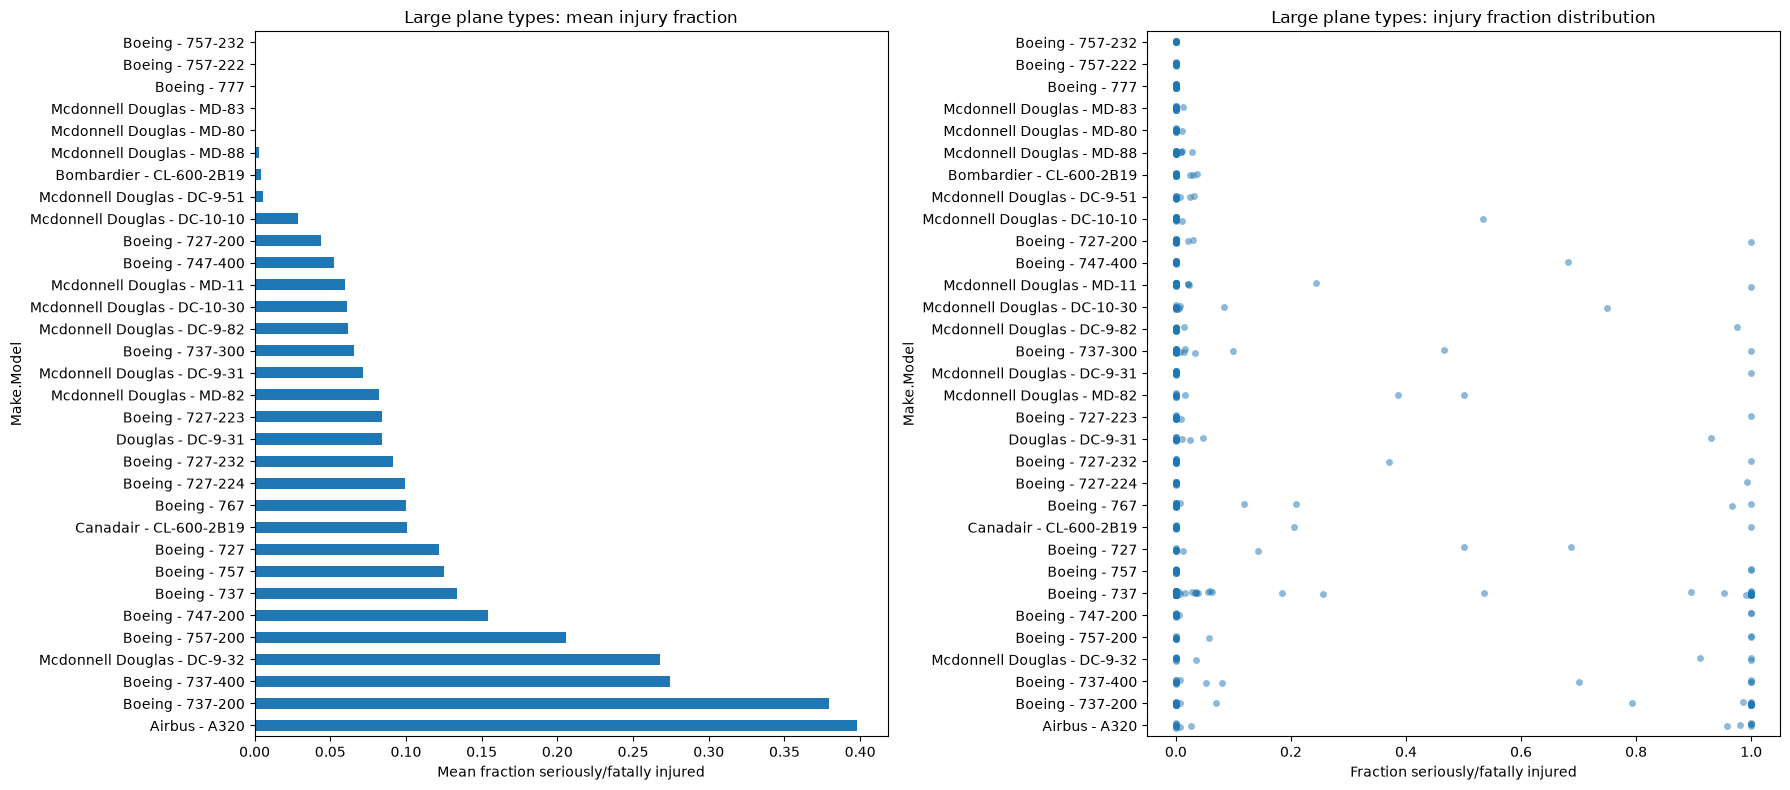

In [11]:
large = cleaned_df[cleaned_df['Plane.Size'] == 'Large']

# Keep only plane types with at least 10 accidents
counts = large['Make.Model'].value_counts()
large = large[large['Make.Model'].isin(counts[counts >= 10].index)]

# Mean injury fraction per plane type, lowest first
large_models = large.groupby('Make.Model')['Fraction.Serious.Fatal'].mean().sort_values()
order = large_models.index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Left: mean injury fraction
large_models.plot(kind='barh', ax=axes[0], title='Large plane types: mean injury fraction')
axes[0].invert_yaxis()   # lowest at the top, matching the strip plot
axes[0].set_xlabel('Mean fraction seriously/fatally injured')

# Right: distribution (one dot per accident)
sns.stripplot(data=large, x='Fraction.Serious.Fatal', y='Make.Model',
              order=order, alpha=0.5, ax=axes[1])
axes[1].set_title('Large plane types: injury fraction distribution')
axes[1].set_xlabel('Fraction seriously/fatally injured')

plt.tight_layout()
plt.show()


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

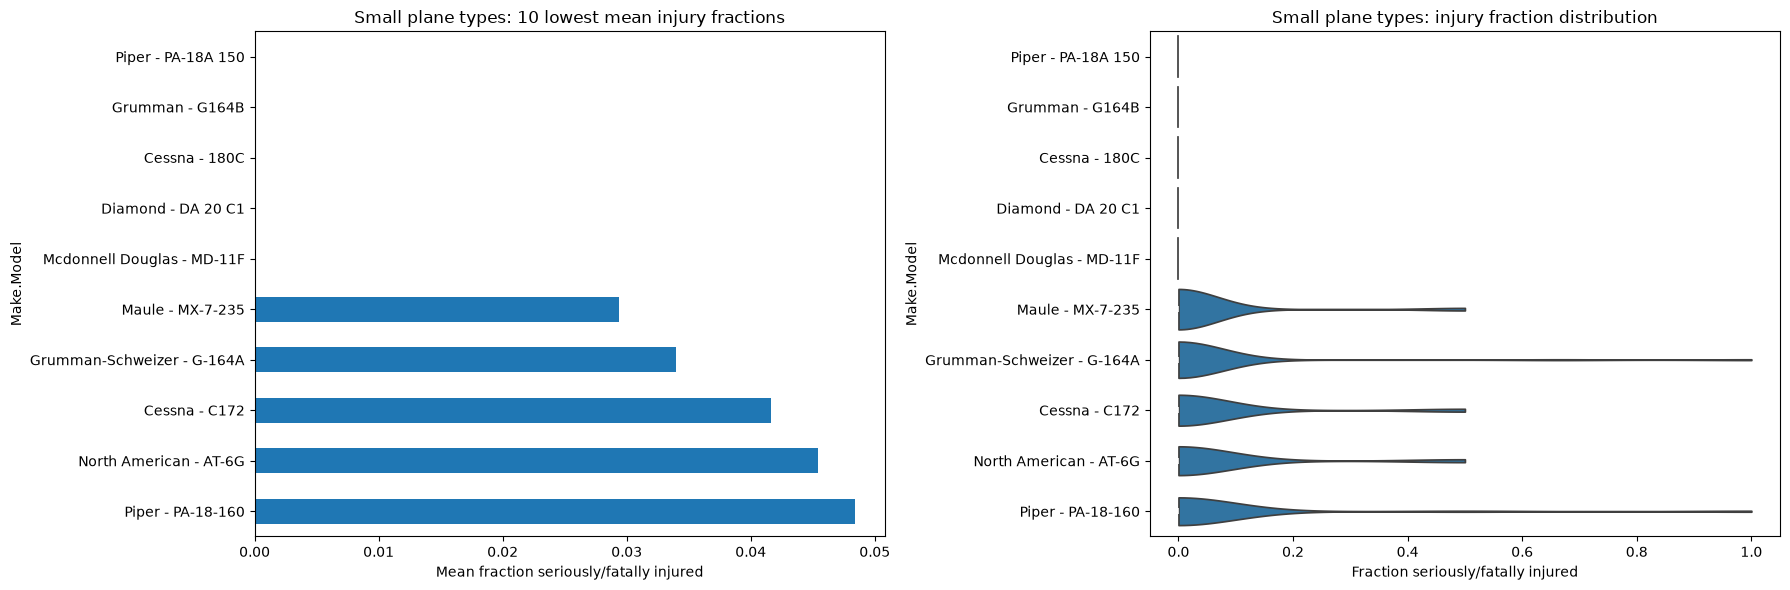

In [12]:
small = cleaned_df[cleaned_df['Plane.Size'] == 'Small']

# Keep only plane types with at least 10 accidents
counts = small['Make.Model'].value_counts()
small = small[small['Make.Model'].isin(counts[counts >= 10].index)]

# Mean injury fraction per plane type: keep the 10 lowest
small_models = small.groupby('Make.Model')['Fraction.Serious.Fatal'].mean().sort_values().head(10)
order = small_models.index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: mean injury fraction
small_models.plot(kind='barh', ax=axes[0], title='Small plane types: 10 lowest mean injury fractions')
axes[0].invert_yaxis()   # lowest at the top, matching the violin plot
axes[0].set_xlabel('Mean fraction seriously/fatally injured')

# Right: distribution, only for those 10 plane types
sns.violinplot(data=small[small['Make.Model'].isin(order)],
               x='Fraction.Serious.Fatal', y='Make.Model',
               order=order, cut=0, ax=axes[1])
axes[1].set_title('Small plane types: injury fraction distribution')
axes[1].set_xlabel('Fraction seriously/fatally injured')

plt.tight_layout()
plt.show()


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

#### Discussion of Specific Airplane Types

##### Large airplanes

- **Safest types:** several airliners recorded **no serious or fatal injuries in any of their accidents**: the **Boeing 777** and the **Boeing 757-232 and 757-222**. The **McDonnell Douglas MD-80, MD-83 and MD-88** and the **Bombardier CL-600-2B19 (CRJ-200 regional jet)** were almost as good.
- **Highest risk:** the **Airbus A320** , **Boeing 737-200** , **Boeing 737-400** and **McDonnell Douglas DC-9-32**. These are mostly older-generation aircraft, and their high averages come from a small number of catastrophic accidents.
- **Reliability:** most types have only 10–25 accidents, so a single fatal crash can move a type a long way up or down the ranking. The **Boeing 737** gives the most reliable estimate.

**Recommendation (large):** the **Boeing 777**, **Boeing 757-200 series**, **McDonnell Douglas MD-88** and **Bombardier CRJ-200** show the lowest risk of serious injury, combined with low destruction rates. Of these, the Boeing 777 is the strongest choice because it is a modern type still in production and service.

##### Small airplanes

- **Safest types:** the 10 lowest are the **Piper PA-18A-150**, **Grumman G-164B**, **Cessna 180C** and **Diamond DA20-C1**, followed by the **Maule MX-7-235**, **Grumman-Schweizer G-164A**, **Cessna C172**, **North American AT-6G** and **Piper PA-18-160**.
- **Distribution:** the violin plots are concentrated at 0. In 92–100% of these types' accidents, nobody was seriously or fatally injured, and only a couple of types have any accidents at 1.

**Recommendation (small):** the **Maule MX-7-235**, **Piper PA-18-160** and **Diamond DA20-C1** are the best choices. They are professional builds that are still flying, with very low serious-injury fractions and low destruction rates. These results match the make-level analysis, where Maule and Diamond also ranked among the lowest-risk manufacturers.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

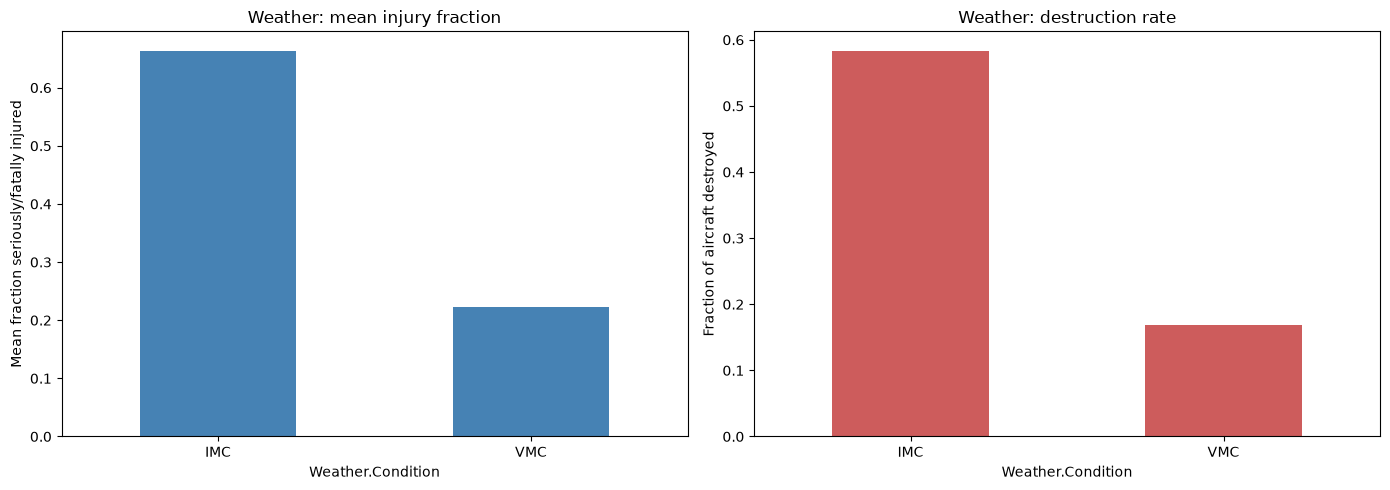

In [13]:
# Factor 1: Weather condition
# VMC = good visibility, IMC = poor visibility (flying by instruments)
weather = cleaned_df[cleaned_df['Weather.Condition'].isin(['VMC', 'IMC'])]

# Mean injury fraction and destruction rate for each weather type
weather_summary = weather.groupby('Weather.Condition')[['Fraction.Serious.Fatal', 'Aircraft.destroyed']].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

weather_summary['Fraction.Serious.Fatal'].plot(kind='bar', ax=axes[0], color='steelblue',
                                               title='Weather: mean injury fraction')
axes[0].set_ylabel('Mean fraction seriously/fatally injured')

weather_summary['Aircraft.destroyed'].plot(kind='bar', ax=axes[1], color='indianred',
                                           title='Weather: destruction rate')
axes[1].set_ylabel('Fraction of aircraft destroyed')

for ax in axes:
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

#### Factor 1: Weather Condition

**Analysis.** I compared accidents in two weather conditions: **VMC** and **IMC**. Rows with unknown or missing weather were left out. For each condition I calculated the mean fraction of people on board who were seriously or fatally injured, and the share of aircraft that were destroyed.

**Findings.**
- Accidents in IMC are far more severe. On average, **66% of the people on board** were seriously or fatally injured, compared with **22% in VMC**, about **3 times higher**.
- The destruction rate shows the same pattern: **58% of aircraft were destroyed** in IMC accidents, compared with **17%** in VMC.

**Interpretation.** When visibility is poor, pilots can lose their sense of orientation or fly into terrain they can't see. These accidents tend to happen at speed and are rarely survivable. Most accidents happen in good weather because most flying is done in good weather, but **an accident in IMC is much more likely to be deadly and to destroy the aircraft**.

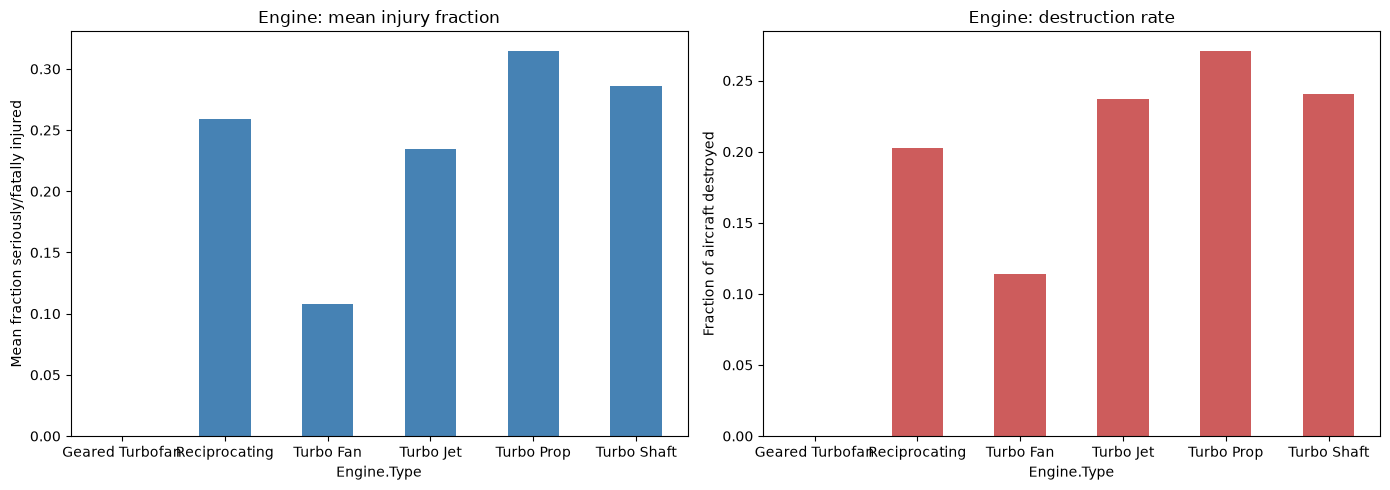

In [14]:
## Factor 2: Engine Type

engine = cleaned_df[cleaned_df['Engine.Type'].notna() & (cleaned_df['Engine.Type'] != 'Unknown')]

# Mean injury fraction and destruction rate for each engine type
engine_summary = engine.groupby('Engine.Type')[['Fraction.Serious.Fatal', 'Aircraft.destroyed']].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

engine_summary['Fraction.Serious.Fatal'].plot(kind='bar', ax=axes[0], color='steelblue',
                                               title='Engine: mean injury fraction')
axes[0].set_ylabel('Mean fraction seriously/fatally injured')

engine_summary['Aircraft.destroyed'].plot(kind='bar', ax=axes[1], color='indianred',
                                           title='Engine: destruction rate')
axes[1].set_ylabel('Fraction of aircraft destroyed')

for ax in axes:
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

#### Factor 2: Engine Type

**Analysis.** I grouped accidents by engine type. Rows with a missing or "Unknown" engine type were removed, and so were types with fewer than 50 accidents, because their averages wouldn't be reliable. For each engine type I calculated the mean injury fraction and the destruction rate.

**Findings.**
- **Turbofan** aircraft have by far the lowest values.
- **Turboprop** aircraft are the most dangerous in an accident. Reciprocating (piston) engines, which power most small planes and account for most of the data, are in the middle .

**Interpretation.** Engine type is closely linked to plane size. Turbofans power most airliners and modern business jets, which are built to stricter certification standards, are flown by professional crews and are operated by airlines with strong safety procedures. So part of the turbofan advantage comes from the type of aircraft and operation, not only from the engine. Even so, for the client this means **turbofan-powered aircraft carry the lowest risk of serious injury and of losing the aircraft**. Turboprops, which are common in regional and bush flying, carry the highest.